# Validate Storage Container
Current storage folder:
- storage/
-    |-----checkpoints/
-    |-----data/


In [4]:
import sys, os
from dotenv import load_dotenv
from pathlib import Path
from src.dataset import load_cached_paths, download_dataset
from src.model import load_model

load_dotenv()
STORAGE_DIR = os.getenv('STORAGE_DIR')

In [5]:
def valStorage():
    # Check exists
    if not Path(STORAGE_DIR).exists():
        print(f"Could not find storage at \"{STORAGE_DIR}\"")
        return
    else:
        print(f"Found storage at \"{STORAGE_DIR}\"")

    # Check dataset
    print(f"Checking for dataset...")
    dataset_paths = load_cached_paths()
    download = input(f"Found {len(dataset_paths)} downloaded scores. Download? (y/n)")
    if download == 'y':
        download_dataset(log=print, progress=lambda i, n: None, max_files=1000000)
        dataset_paths = load_cached_paths()
        print(f"Downloaded {len(dataset_paths)} scores.")

    print(f"Checking for checkpoints")
    checkpoint_dir = Path(STORAGE_DIR) / 'checkpoints'
    if not checkpoint_dir.exists():
        print("Could not find checkpoint path.")
    else:
        print("Found checkpoint folder. Scanning for infill model...")
        _, config = load_model()
        print(f"Found model config trained with {len(config.get('epoches'))} epoches")
        print(f"Found config: {config.__str__()}")


valStorage()

Found storage at "./storage"
Checking for dataset...
Checking for checkpoints
Found checkpoint folder. Scanning for infill model...
Found model config trained with 808 epoches
Found config: {'vocab_size': 415, 'd_model': 256, 'n_heads': 8, 'n_layers': 4, 'max_seq_len': 2048, 'dropout': 0.1, 'epoches': [[2.955204677307743, 2.6238090991973877], [2.508154775904513, 2.447759222984314], [2.413598821080964, 2.394601845741272], [2.3460873351700005, 2.3869483709335326], [2.2988637117133743, 2.3480711221694945], [2.259260718849884, 2.3331925868988037], [2.2271603414382057, 2.2961454153060914], [2.2028255174899924, 2.307954263687134], [2.1880657412539954, 2.2639389038085938], [2.1563228622250175, 2.28260817527771], [2.1421038008284294, 2.256501388549805], [2.113516512958483, 2.2478256702423094], [2.0977609911184203, 2.249330496788025], [2.073472836921955, 2.248413586616516], [2.0693925920574143, 2.2386965990066527], [2.048179455187129, 2.2584883689880373], [2.0334322836207246, 2.2320435285568236

### Display Model Epoches

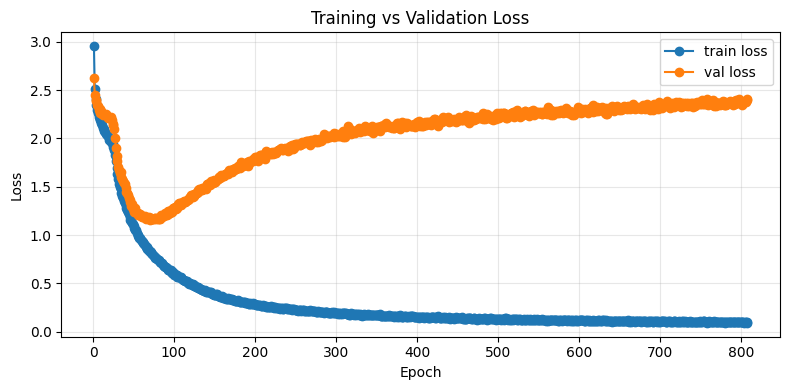

In [7]:
import json, matplotlib.pyplot as plt
from pathlib import Path

cfg_path = Path(STORAGE_DIR) / "checkpoints/config.json"
if not cfg_path.exists():
    print("No config.json found — train the model first.")
else:
    epoches = json.loads(cfg_path.read_text()).get("epoches", [])
    if not epoches:
        print("No epoch data yet — run the training cell first.")
    else:
        train_losses = [e[0] for e in epoches]
        val_losses = [e[1] for e in epoches]
        xs = range(1, len(epoches) + 1)

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(xs, train_losses, marker="o", label="train loss")
        ax.plot(xs, val_losses, marker="o", label="val loss")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_title("Training vs Validation Loss")
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()